In [1]:
from nupack import *

# =========================================================
# model
# =========================================================
# PEN toolbox / Nt.BstNBI reactions are often run near 37-45 C.
# Change celsius / salt conditions here to match your experiment.

model = Model(
    material='dna',
    celsius=38.5,
    sodium=0.050,
    magnesium=0.007,

)

# =========================================================
# sequences from the PEN toolbox Oligator table
# =========================================================
# Table notation:
#   T1  A*A*CAGACTCGA-AACAGACTCGA-3'P
#   T2  G*C*ATGACTCAT-AACAGACTCGA-3'P
#   T3  T*T*ACTCGAAACAGACT-GCATGACTCAT-3'P
#   alpha  TCGAGTCTGTT
#   beta   ATGAGTCATGC
#   Inh    AGTCTGTTTCGAGTAA
# NUPACK receives only unmodified DNA bases; chemical modifications are
# represented by the names/comments above, not by the sequence strings.

seq = {
    'T1': 'AACAGACTCGAAACAGACTCGA',
    'T2': 'GCATGACTCATAACAGACTCGA',
    'T3': 'TTACTCGAAACAGACTCGA',
    'alpha': 'TCGAGTCTGTT',
    'beta': 'ATGAGTCATGC',
    'Inh': 'AGTCTGTTTCGAGTAA',
    'P1': 'TAAGTTCGCTGTGGCTTTACCTGCACG',
    'P2': 'CAACGTGCAGGTGCCACAGCGTGG',
    'Link1-template': 'ACAGTTAAGTTCGCTGTGGCTTTACCTGCACGCATGATGGGTGCGTGCAGGTAAAGCCACATGAACAGACTCGA',
    'Link2-template': 'TCATGCAACGTGCAGGTGCCACAGCGAACTTAACTGTTGTGGCACCTGCACGCACCCAAACAGACTCGA',
    'Link1': 'CATGTGGCTTTACCTGCACGCACCCATCATGCGTGCAGGTAAAGCCACAGCGAACTTAACTGT',
    'Link2': 'TGGGTGCGTGCAGGTGCCACAACAGTTAAGTTCGCTGTGGCACCTGCACGTTGCATGA',
}
T1 = Strand(seq['T1'], name='Template1')
T2 = Strand(seq['T2'], name='Template2')
T3 = Strand(seq['T3'], name='Template3')
alpha = Strand(seq['alpha'], name='A')
beta = Strand(seq['beta'], name='B')
Inh = Strand(seq['Inh'], name='Inh')
P1 = Strand(seq['P1'], name='Pendant1')
P2 = Strand(seq['P2'], name='Pendant2')
Link1_template = Strand(seq['Link1-template'], name='Linker1-Template')
Link2_template = Strand(seq['Link2-template'], name='Linker2-Template')
Link1 = Strand(seq['Link1'], name='Linker1')
Link2 = Strand(seq['Link2'], name='Linker2')


In [8]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {
    T1: 1e-9,
    T2: 1e-9,
    T3: 1e-9,
    alpha: 1e-9,
    beta: 1e-9,
    Inh: 1e-9,
    Link1: 1e-9,
    Link2: 1e-9,
    Link1_template:1e-9,
    Link2_template:1e-9
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=4),
    name='all_oligator',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

#tube_results


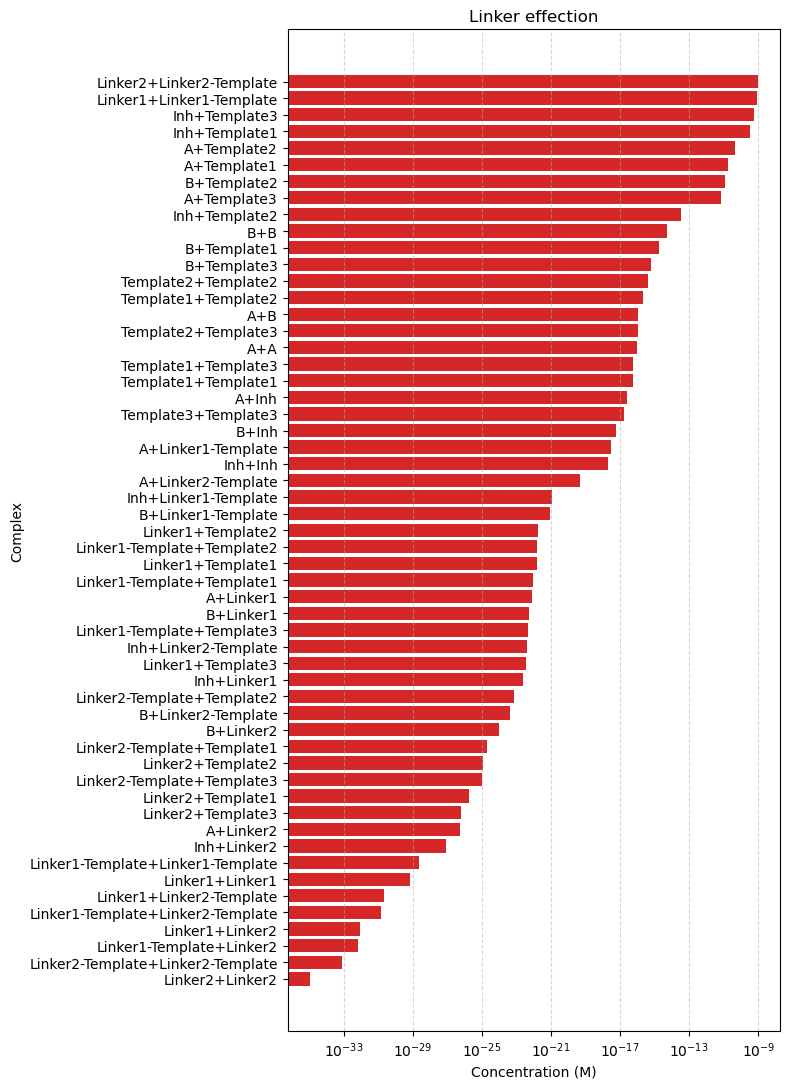

In [13]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["all_oligator"]

data = []
for comp, result in tube.complex_concentrations.items():
    if len(comp.strands) == 2:
        # 複合体名
        name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
        conc = result

        data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位10件
top10 = data

names = [x[0] for x in top10]
concs = [x[1] for x in top10]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(8, max(6, len(data) * 0.20)))
plt.barh(names, concs, color="#d62728")
plt.xscale("log")
plt.grid(axis="x", which="both", linestyle="--", alpha=0.5)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)")
plt.ylabel("Complex")
plt.title("Linker effection")
plt.tight_layout()
plt.show()